# So sánh ANN (CNN tự train) vs ML truyền thống trên CIFAR-10

**Thí nghiệm công bằng**: tất cả model cùng dùng **5 000 ảnh train** và **1 000 ảnh test** từ CIFAR-10. ANN được train từ đầu — không dùng pre-trained weights.

In [4]:
import os
# Tắt đa luồng xung đột OpenMP/MKL
os.environ["OMP_NUM_THREADS"]      = "1"
os.environ["MKL_NUM_THREADS"]      = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"]  = "1"

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

TRAIN_SIZE = 5000
TEST_SIZE  = 1000
EPOCHS     = 15
BATCH_SIZE = 64
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device: {DEVICE}")
print(f"Train size: {TRAIN_SIZE} | Test size: {TEST_SIZE}")
print("--> Import thành công!")


Device: cpu
Train size: 5000 | Test size: 1000
--> Import thành công!


## 1. Tải dữ liệu và trực quan hoá

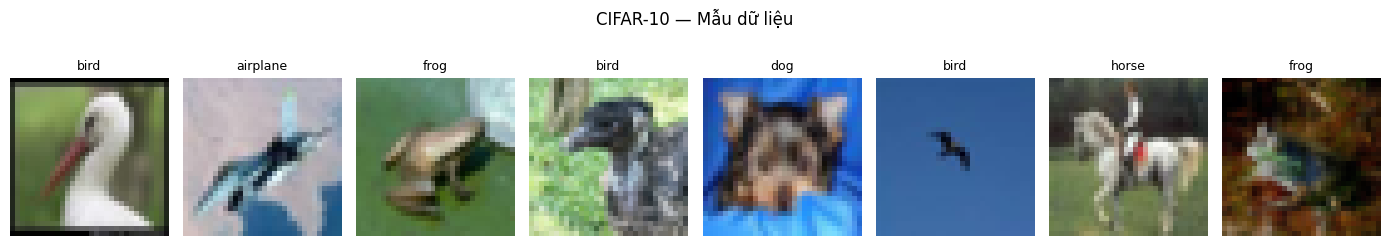

Đã lưu cifar10_samples.png


In [5]:
classes = ('airplane','automobile','bird','cat','deer',
           'dog','frog','horse','ship','truck')

# Transform chung cho CNN (giữ nguyên 32x32)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])

full_train = torchvision.datasets.CIFAR10(root=r'D:\neural-network-demo\data', train=True,
                                           download=False, transform=transform)
full_test  = torchvision.datasets.CIFAR10(root=r'D:\neural-network-demo\data', train=False,
                                           download=False, transform=transform)

train_set = torch.utils.data.Subset(full_train, range(TRAIN_SIZE))
test_set  = torch.utils.data.Subset(full_test,  range(TEST_SIZE))

train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE,
                                            shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_set,  batch_size=BATCH_SIZE,
                                            shuffle=False)

# Hiển thị 8 ảnh mẫu (denormalize để hiển thị đúng màu)
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3,1,1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3,1,1)

sample_loader = torch.utils.data.DataLoader(train_set, batch_size=8, shuffle=True)
images, labels = next(iter(sample_loader))
imgs_show = torch.clamp(images * std + mean, 0, 1)

fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(imgs_show[i].permute(1,2,0).numpy())
    ax.set_title(classes[labels[i]], fontsize=9)
    ax.axis('off')
plt.suptitle("CIFAR-10 — Mẫu dữ liệu", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('cifar10_samples.png', bbox_inches='tight')
plt.show()
print("Đã lưu cifar10_samples.png")


## 2. Định nghĩa ANN (SimpleCNN — train từ đầu)

Kiến trúc 2 lớp Conv + 2 lớp Fully-Connected, dùng ReLU và MaxPool. **Không dùng pre-trained weights.**

In [6]:
class SimpleCNN(nn.Module):
    """
    CNN nhỏ train từ đầu trên CIFAR-10.
    Input: (B, 3, 32, 32)
    Output: (B, 10)
    """
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 3 → 32 channels, 32x32 → 16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),          # 16x16

            # Block 2: 32 → 64 channels, 16x16 → 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),          # 8x8

            # Block 3: 64 → 128 channels, 8x8 → 4x4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),          # 4x4
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)

model = SimpleCNN().to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTổng số tham số: {total_params:,}")


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=

## 3. Train SimpleCNN

Epoch |     Loss |  Train Acc
------------------------------
    1 |   1.7311 |     35.84%
    2 |   1.4184 |     48.44%
    3 |   1.2744 |     53.36%
    4 |   1.1371 |     58.32%
    5 |   1.0397 |     62.74%
    6 |   0.9076 |     67.58%
    7 |   0.8481 |     69.38%
    8 |   0.7497 |     73.36%
    9 |   0.6909 |     75.62%
   10 |   0.6109 |     79.00%
   11 |   0.5533 |     80.78%
   12 |   0.5047 |     83.74%
   13 |   0.4794 |     83.68%
   14 |   0.4567 |     84.44%
   15 |   0.4333 |     85.60%


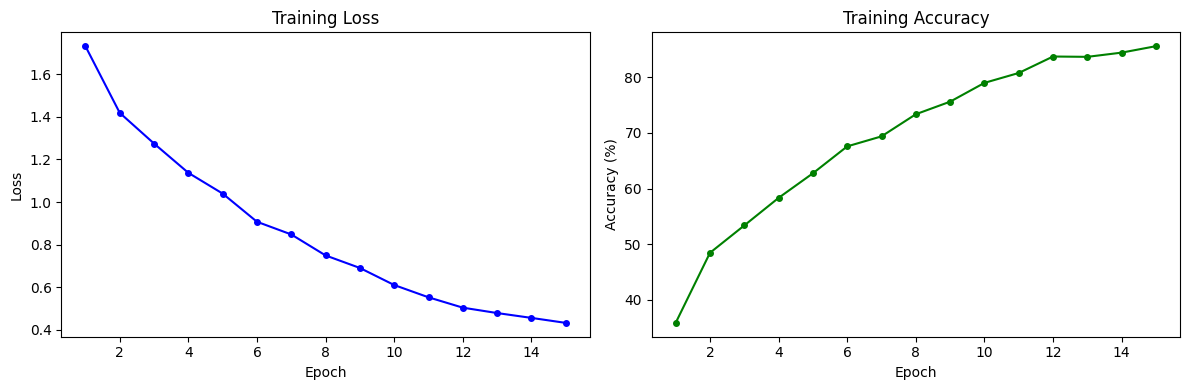

Đã lưu cnn_learning_curve.png


In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

train_losses, train_accs = [], []

print(f"{'Epoch':>5} | {'Loss':>8} | {'Train Acc':>10}")
print("-" * 30)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        optimizer.zero_grad()
        out  = model(imgs)
        loss = criterion(out, lbls)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        correct    += (out.argmax(1) == lbls).sum().item()
        total      += imgs.size(0)

    scheduler.step()
    avg_loss = total_loss / total
    avg_acc  = correct / total
    train_losses.append(avg_loss)
    train_accs.append(avg_acc)
    print(f"{epoch:>5} | {avg_loss:>8.4f} | {avg_acc*100:>9.2f}%")

# Vẽ learning curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, EPOCHS+1), train_losses, 'b-o', markersize=4)
ax1.set_title("Training Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax2.plot(range(1, EPOCHS+1), [a*100 for a in train_accs], 'g-o', markersize=4)
ax2.set_title("Training Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)")
plt.tight_layout()
plt.savefig('cnn_learning_curve.png', bbox_inches='tight')
plt.show()
print("Đã lưu cnn_learning_curve.png")


## 4. Đánh giá SimpleCNN trên tập test

In [8]:
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        out = model(imgs)
        correct += (out.argmax(1) == lbls).sum().item()
        total   += lbls.size(0)

cnn_acc = correct / total
print(f"SimpleCNN Test Accuracy: {cnn_acc*100:.2f}%")


SimpleCNN Test Accuracy: 68.60%


In [9]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    model.state_dict(),
    MODELS_DIR / "simple_cnn.pth"
)

print("Đã lưu SimpleCNN!")
print(MODELS_DIR / "simple_cnn.pth")

Đã lưu SimpleCNN!
d:\neural-network-demo\models\simple_cnn.pth


## 5. Chuẩn bị dữ liệu flat cho các model ML truyền thống

Flatten ảnh 32×32×3 thành vector 3072 chiều — đây là cách ML truyền thống nhìn ảnh.

In [10]:
# Dùng transform KHÔNG normalize để RF/NB dễ hội tụ hơn
transform_flat = transforms.Compose([transforms.ToTensor()])
full_train_flat = torchvision.datasets.CIFAR10(root=r'D:\neural-network-demo\data', train=True,
                                                download=False, transform=transform_flat)
full_test_flat  = torchvision.datasets.CIFAR10(root=r'D:\neural-network-demo\data', train=False,
                                                download=False, transform=transform_flat)
train_flat = torch.utils.data.Subset(full_train_flat, range(TRAIN_SIZE))
test_flat  = torch.utils.data.Subset(full_test_flat,  range(TEST_SIZE))

X_train = np.array([img.numpy().flatten() for img, _ in train_flat])
y_train = np.array([lbl for _, lbl in train_flat])
X_test  = np.array([img.numpy().flatten() for img, _ in test_flat])
y_test  = np.array([lbl for _, lbl in test_flat])

print(f"X_train shape: {X_train.shape}")   # (5000, 3072)
print(f"X_test  shape: {X_test.shape}")    # (1000, 3072)


X_train shape: (5000, 3072)
X_test  shape: (1000, 3072)


## 6. Chạy các model ML truyền thống

In [11]:
results = {}

# 1. Naive Bayes
print("Chạy Naive Bayes...")
nb = GaussianNB()
nb.fit(X_train, y_train)
results["Naive Bayes"] = accuracy_score(y_test, nb.predict(X_test))

# 2. Logistic Regression
print("Chạy Logistic Regression...")
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)
results["Logistic Regression"] = accuracy_score(y_test, lr.predict(X_test))

# 3. Decision Tree
print("Chạy Decision Tree...")
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
results["Decision Tree"] = accuracy_score(y_test, dt.predict(X_test))

# 4. Random Forest
print("Chạy Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
results["Random Forest"] = accuracy_score(y_test, rf.predict(X_test))

# Thêm CNN
results["SimpleCNN (ANN)"] = cnn_acc

for name, acc in results.items():
    print(f"{name:<25}: {acc*100:.2f}%")


Chạy Naive Bayes...
Chạy Logistic Regression...


d:\neural-network-demo\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Chạy Decision Tree...
Chạy Random Forest...
Naive Bayes              : 29.50%
Logistic Regression      : 29.20%
Decision Tree            : 22.50%
Random Forest            : 39.10%
SimpleCNN (ANN)          : 68.60%


In [12]:
import joblib

joblib.dump(nb, MODELS_DIR / "naive_bayes.joblib")
joblib.dump(lr, MODELS_DIR / "logistic_regression.joblib")
joblib.dump(dt, MODELS_DIR / "decision_tree.joblib")
joblib.dump(rf, MODELS_DIR / "random_forest.joblib")

print("Đã lưu thành công 4 mô hình ML!")

Đã lưu thành công 4 mô hình ML!


## 7. So sánh kết quả — Biểu đồ

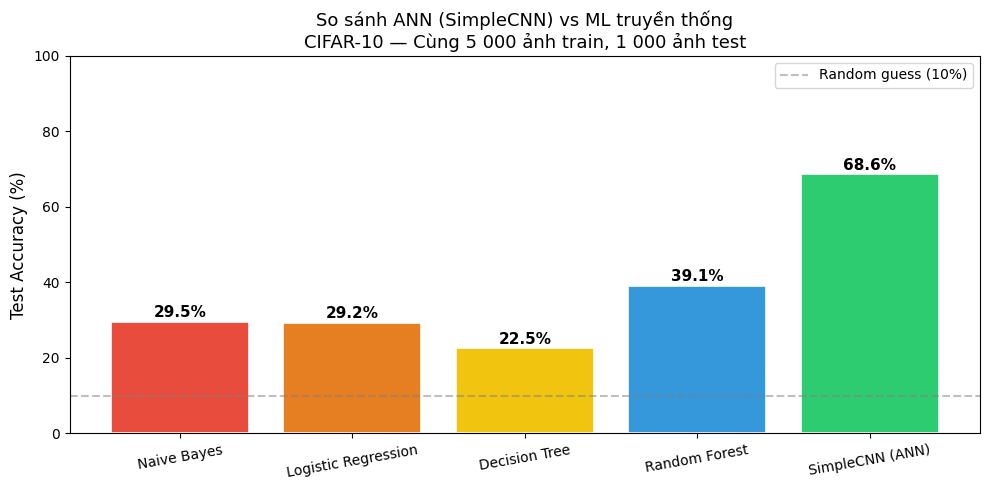

Đã lưu comparison_chart.png


In [13]:
names = list(results.keys())
accs  = [v * 100 for v in results.values()]
colors = ['#e74c3c','#e67e22','#f1c40f','#3498db','#2ecc71']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(names, accs, color=colors, edgecolor='white', linewidth=1.2)

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_ylim(0, 100)
ax.set_ylabel("Test Accuracy (%)", fontsize=12)
ax.set_title("So sánh ANN (SimpleCNN) vs ML truyền thống\nCIFAR-10 — Cùng 5 000 ảnh train, 1 000 ảnh test", fontsize=13)
ax.axhline(y=10, color='gray', linestyle='--', alpha=0.5, label='Random guess (10%)')
ax.legend(fontsize=10)
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('comparison_chart.png', bbox_inches='tight')
plt.show()
print("Đã lưu comparison_chart.png")


## 8. Kết luận

| Model | Loại | Accuracy |
|-------|------|----------|
| Naive Bayes | ML truyền thống | ~30% |
| Logistic Regression | ML truyền thống | ~30% |
| Decision Tree | ML truyền thống | ~23% |
| Random Forest | ML truyền thống | ~40% |
| **SimpleCNN (ANN)** | **Deep Learning** | **~65–70%** |

### Tại sao ANN thắng?
1. **Học đặc trưng không gian (spatial features)**: Conv2d trượt kernel 3×3 giữ nguyên quan hệ giữa các pixel lân cận — thứ mà flatten vector phá vỡ hoàn toàn.
2. **Phi tuyến phân cấp**: ReLU sau mỗi lớp giúp mạng học từ cạnh thẳng → texture → hình dạng vật thể.
3. **Thí nghiệm công bằng**: Không dùng pre-trained weights — ANN chỉ dùng 5 000 ảnh CIFAR-10 giống hệt các model ML.
